# Chapitre 4 - Exercices 4.6 à 4.9

- **4.6** : convergence du perceptron ;
- **4.7** : un critère « tous points » pour les hyperplans séparateurs ;
- **4.8** : modèle gaussien à centroïdes de rang réduit et LDA de rang réduit ;
- **4.9** : programmer la QDA et l'appliquer aux voyelles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg, optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch04_classification as c4
set_style()

## Exercice 4.6 : Convergence du perceptron

**Énoncé.** On dispose de $N$ points $x_i\in\mathbb{R}^p$ en position générale, d'étiquettes
$y_i\in\{-1,1\}$, et l'on suppose les classes linéairement séparables. Montrer que
l'algorithme du perceptron converge vers un hyperplan séparateur en un nombre fini
d'étapes :

(a) On note un hyperplan $f(x) = \beta_1^Tx+\beta_0 = 0$, ou $\beta^Tx^* = 0$ avec
$x^* = (x,1)$ et $\beta = (\beta_1,\beta_0)$. Soit $z_i = x_i^*/\|x_i^*\|$. Montrer que la
séparabilité implique l'existence d'un $\beta_{\text{sep}}$ tel que $y_i\beta_{\text{sep}}^Tz_i\ge1$ pour tout $i$.

(b) Étant donné $\beta_{\text{old}}$, le perceptron choisit un point $z_i$ mal classé et
effectue $\beta_{\text{new}}\leftarrow\beta_{\text{old}}+y_iz_i$. Montrer que
$\|\beta_{\text{new}}-\beta_{\text{sep}}\|^2\le\|\beta_{\text{old}}-\beta_{\text{sep}}\|^2-1$,
et en déduire que l'algorithme converge vers un hyperplan séparateur en au plus
$\|\beta_{\text{start}}-\beta_{\text{sep}}\|^2$ étapes (Ripley, 1996).

### (a) Existence de $\beta_{\text{sep}}$

Les classes étant séparables, il existe $\beta = (\beta_1,\beta_0)$ tel que
$y_i(\beta_1^Tx_i+\beta_0) > 0$, c'est-à-dire $y_i\beta^Tx_i^* > 0$, pour tout $i$.

- $\|x_i^*\|\ge1 > 0$ (sa dernière coordonnée vaut 1), donc $z_i$ est bien défini et
  $y_i\beta^Tz_i = y_i\beta^Tx_i^*/\|x_i^*\| > 0$.
- Il y a un nombre **fini** de points, donc $m = \min_iy_i\beta^Tz_i$ est atteint et $m > 0$.

Posons $\beta_{\text{sep}} = \beta/m$. Par linéarité, $y_i\beta_{\text{sep}}^Tz_i = (y_i\beta^Tz_i)/m\ge1$ pour tout $i$. $\square$

### (b) Décroissance de la distance à $\beta_{\text{sep}}$

On développe le carré de la norme ($\|a+b\|^2 = \|a\|^2+2a^Tb+\|b\|^2$) :
$$\|\beta_{\text{new}}-\beta_{\text{sep}}\|^2 = \|\beta_{\text{old}}-\beta_{\text{sep}}\|^2 + 2y_i(\beta_{\text{old}}-\beta_{\text{sep}})^Tz_i + y_i^2\|z_i\|^2.$$
Examinons les deux derniers termes :

- $y_i^2\|z_i\|^2 = 1$ car $y_i = \pm1$ et $\|z_i\| = 1$ ;
- $y_i\beta_{\text{old}}^Tz_i\le0$ car $z_i$ est **mal classé** par $\beta_{\text{old}}$ ;
- $y_i\beta_{\text{sep}}^Tz_i\ge1$ par (a).

D'où $2y_i(\beta_{\text{old}}-\beta_{\text{sep}})^Tz_i\le 2(0-1) = -2$, et
$$\|\beta_{\text{new}}-\beta_{\text{sep}}\|^2\le\|\beta_{\text{old}}-\beta_{\text{sep}}\|^2-2+1 = \|\beta_{\text{old}}-\beta_{\text{sep}}\|^2-1.$$

**Conclusion.** Après $k$ mises à jour, $0\le\|\beta^{(k)}-\beta_{\text{sep}}\|^2\le\|\beta_{\text{start}}-\beta_{\text{sep}}\|^2-k$,
donc $k\le\|\beta_{\text{start}}-\beta_{\text{sep}}\|^2$ : le nombre de mises à jour est
fini. Quand l'algorithme s'arrête, plus aucun point n'est mal classé, c'est-à-dire
$y_i\beta^Tz_i > 0$ pour tout $i$ - et comme $\beta^Tz_i$ a le signe de $\beta^Tx_i^*$,
l'hyperplan $\beta^Tx^* = 0$ **sépare** les données. $\square$

> **Remarques.**
> - La borne vaut pour **tout** $\beta_{\text{sep}}$ admissible ; la meilleure s'obtient
>   avec celui de norme minimale. En partant de $\beta_{\text{start}} = 0$, elle vaut
>   $\|\beta_{\text{sep}}\|^2 = 1/\gamma^2$, où
>   $\gamma = \max_{\|\beta\|=1}\min_iy_i\beta^Tz_i$ est la « marge » des $z_i$ : plus les
>   classes sont proches, plus la borne est grande (troisième problème du perceptron cité
>   dans le livre).
> - L'ordre de visite des points mal classés est quelconque : la preuve ne l'utilise pas.

### Vérification numérique

On calcule le $\beta_{\text{sep}}$ de norme minimale, solution de
$\min\|\beta\|^2$ sous $y_i\beta^Tz_i\ge1$ (programmation quadratique avec SLSQP), puis on
fait tourner le perceptron normalisé (fonction `perceptron(..., normalize=True)`) avec
différents ordres de parcours.

In [2]:
rng = np.random.RandomState(3)
Xp = np.vstack([rng.randn(25, 2) * 0.6 + [-1.0, 0.5], rng.randn(25, 2) * 0.6 + [1.0, -0.3]])
yp = np.repeat([-1, 1], 25)
r0 = c4.perceptron(Xp, yp, max_epochs=10000)
print("Données séparables :", r0["converged"])
Z = np.column_stack([Xp, np.ones(len(yp))])
Z /= np.linalg.norm(Z, axis=1, keepdims=True)
A = yp[:, None] * Z
start = r0["beta"] / np.min(A @ r0["beta"])                 # point admissible
sol = optimize.minimize(lambda b: b @ b, start, jac=lambda b: 2 * b, method="SLSQP",
                        constraints=[{"type": "ineq", "fun": lambda b: A @ b - 1, "jac": lambda b: A}],
                        options={"ftol": 1e-12, "maxiter": 500})
beta_sep = sol.x
borne = beta_sep @ beta_sep
print("min_i y_i beta_sep^T z_i = %.4f ;  borne ||beta_sep||^2 = %.1f" % (np.min(A @ beta_sep), borne))

Données séparables : True
min_i y_i beta_sep^T z_i = 1.0000 ;  borne ||beta_sep||^2 = 556.4


In [3]:
nb = [c4.perceptron(Xp, yp, normalize=True, rng=np.random.RandomState(s))["n_updates"] for s in range(200)]
print("Mises à jour sur 200 ordres de parcours : min %d, médiane %d, max %d (borne %.0f)" % (
    min(nb), np.median(nb), max(nb), borne))

Mises à jour sur 200 ordres de parcours : min 2, médiane 29, max 67 (borne 556)


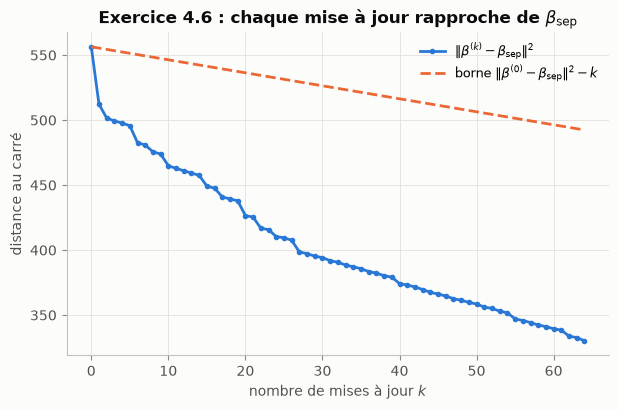

Décroissance d'au moins 1 à chaque pas : True


In [4]:
r = c4.perceptron(Xp, yp, normalize=True, rng=np.random.RandomState(0))
dist2 = np.sum((r["path"] - beta_sep) ** 2, axis=1)
k = np.arange(len(dist2))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(k, dist2, "o-", ms=3, color=BLUE, label=r"$\|\beta^{(k)}-\beta_{\mathrm{sep}}\|^2$")
ax.plot(k, dist2[0] - k, "--", color=ORANGE, label=r"borne $\|\beta^{(0)}-\beta_{\mathrm{sep}}\|^2 - k$")
ax.set_title("Exercice 4.6 : chaque mise à jour rapproche de $\\beta_{\\mathrm{sep}}$")
ax.set_xlabel("nombre de mises à jour $k$")
ax.set_ylabel("distance au carré")
ax.legend()
plt.show()
print("Décroissance d'au moins 1 à chaque pas :", np.all(np.diff(dist2) <= -1 + 1e-9))

La distance au carré décroît d'au moins 1 à chaque mise à jour, et le nombre de mises à
jour reste toujours sous la borne (souvent très en dessous : la borne est pessimiste).

> **À retenir.** Pour des données séparables, chaque correction du perceptron (sur les
> points normalisés $z_i$) réduit d'au moins 1 le carré de la distance à un séparateur
> $\beta_{\text{sep}}$ fixé : l'algorithme s'arrête après au plus
> $\|\beta_{\text{start}}-\beta_{\text{sep}}\|^2$ mises à jour, sur un hyperplan séparant.

## Exercice 4.7 : Un critère sur tous les points

**Énoncé.** On considère le critère
$$D^*(\beta,\beta_0) = -\sum_{i=1}^Ny_i(x_i^T\beta+\beta_0)\qquad\text{(éq. (4.58))},$$
généralisation de (4.41) où l'on somme sur **toutes** les observations (et pas seulement
sur les mal classées). On minimise $D^*$ sous la contrainte $\|\beta\| = 1$. Décrire ce
critère en mots. Résout-il le problème de l'hyperplan séparateur optimal ?

### Interprétation

Avec $\|\beta\| = 1$, la quantité $x_i^T\beta+\beta_0$ est la **distance signée** de $x_i$
à l'hyperplan (cours 3, figure 4.15), et $y_i(x_i^T\beta+\beta_0)$ est positive si $x_i$ est
du bon côté, négative sinon. Minimiser $D^*$, c'est donc **maximiser la somme des distances
signées** des points à l'hyperplan, comptées positivement du bon côté. Contrairement au
perceptron, les points bien classés comptent aussi : un point très éloigné du bon côté
peut « compenser » plusieurs points mal classés.

### Résolution

Notons $N_+$, $N_-$ les effectifs des classes $+1$ et $-1$ et $\bar x_+$, $\bar x_-$ leurs
moyennes. Par linéarité,
$$D^*(\beta,\beta_0) = -\beta^T\underbrace{\sum_iy_ix_i}_{s} - \beta_0\sum_iy_i,\qquad s = N_+\bar x_+ - N_-\bar x_-,\quad \sum_iy_i = N_+-N_-.$$

- **Si $N_+\neq N_-$**, $D^*$ est affine en $\beta_0$ de pente non nulle : en faisant tendre
  $\beta_0$ vers $\pm\infty$ (selon le signe de $N_+-N_-$), $D^*\to-\infty$. Le problème n'a
  **pas de solution** : on repousse l'hyperplan à l'infini, tous les points se retrouvent du
  côté de la classe majoritaire.

- **Si $N_+ = N_-$**, $\beta_0$ disparaît (il n'est pas déterminé) et l'on minimise
  $-\beta^Ts$ sous $\|\beta\| = 1$. Par l'inégalité de Cauchy-Schwarz,
  $-\beta^Ts\ge-\|\beta\|\|s\| = -\|s\|$, avec égalité si et seulement si $\beta = s/\|s\|$.
  Comme $s = N_+(\bar x_+-\bar x_-)$, la solution est
  $$\hat\beta = \frac{\bar x_+-\bar x_-}{\|\bar x_+-\bar x_-\|} :$$
  la direction **joignant les deux centroïdes**.

**Réponse à la question.** Non : ce critère ne résout pas le problème de l'hyperplan
séparateur optimal.

- La direction obtenue ne dépend que des **moyennes** de classe (ni de la covariance, comme
  le ferait la LDA, ni des points proches de la frontière, comme l'hyperplan optimal) ;
- $\beta_0$ est indéterminé (ou le problème est non borné) ;
- même pour des données séparables, l'hyperplan obtenu (quel que soit $\beta_0$) peut ne
  **pas séparer** les classes, alors que l'hyperplan optimal les sépare toujours en
  maximisant la plus petite distance, pas la somme.

### Illustration

Deux classes de même effectif, allongées horizontalement, séparées par la droite
$x_2 = 0$ mais décalées l'une par rapport à l'autre selon $x_1$. La direction des
centroïdes est alors presque horizontale et ne permet pas de les séparer, quel que soit
le seuil choisi.

In [5]:
rng = np.random.RandomState(2)
n7 = 100
X_moins = np.column_stack([rng.uniform(-8, 2, n7), rng.uniform(-1.5, -0.15, n7)])
X_plus = np.column_stack([rng.uniform(-2, 8, n7), rng.uniform(0.15, 1.5, n7)])
X7 = np.vstack([X_moins, X_plus])
y7 = np.repeat([-1, 1], n7)
print("Effectifs :", np.sum(y7 == -1), np.sum(y7 == 1))

Effectifs : 100 100


In [6]:
beta_star = X7[y7 == 1].mean(axis=0) - X7[y7 == -1].mean(axis=0)
beta_star /= np.linalg.norm(beta_star)
proj = X7 @ beta_star
seuils = np.sort(proj)
meilleure_err = min(np.mean(np.sign(proj - t + 1e-12) != y7) for t in seuils)
opt7 = c4.optimal_hyperplane(X7, y7)
err_opt = np.mean(np.sign(X7 @ opt7["coef"] + opt7["intercept"]) != y7)
print("Critère D* : direction (%.3f, %.3f), meilleure erreur sur tous les seuils : %.3f" % (*beta_star, meilleure_err))
print("Hyperplan optimal : erreur %.3f, marge %.3f" % (err_opt, opt7["margin"]))

Critère D* : direction (0.973, 0.232), meilleure erreur sur tous les seuils : 0.115
Hyperplan optimal : erreur 0.000, marge 0.197


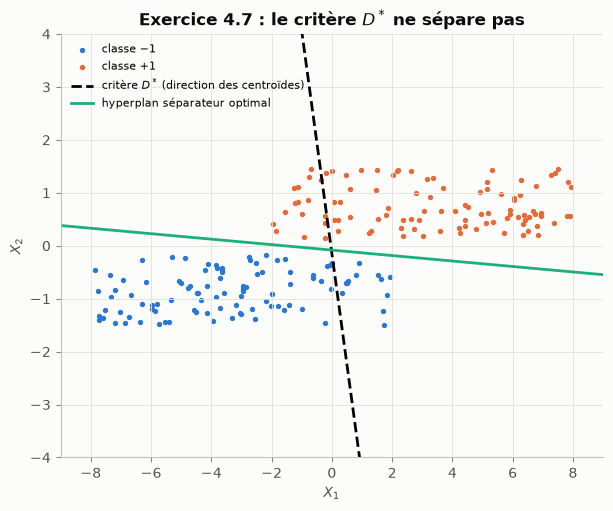

In [7]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(*X7[y7 == -1].T, s=8, color=BLUE, label="classe $-1$")
ax.scatter(*X7[y7 == 1].T, s=8, color=ORANGE, label="classe $+1$")
lims = (-9, 9)
ax.set_xlim(lims)
ax.set_ylim(lims)
xs = np.array(lims, float)
t_mid = 0.5 * (X7[y7 == 1].mean(axis=0) + X7[y7 == -1].mean(axis=0)) @ beta_star
ax.plot(xs, (t_mid - beta_star[0] * xs) / beta_star[1], color="k", ls="--",
        label="critère $D^*$ (direction des centroïdes)")
ax.plot(xs, -(opt7["intercept"] + opt7["coef"][0] * xs) / opt7["coef"][1], color=COLORS[2],
        label="hyperplan séparateur optimal")
ax.set_title("Exercice 4.7 : le critère $D^*$ ne sépare pas")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_ylim(-4, 4)
ax.legend(fontsize=8, loc="upper left")
plt.show()

> **À retenir.** $D^*$ mesure la somme des distances signées de tous les points à
> l'hyperplan. Sa minimisation sous $\|\beta\| = 1$ est non bornée si les effectifs
> diffèrent, et donne sinon la direction des centroïdes avec un $\beta_0$ arbitraire : ce
> n'est pas l'hyperplan séparateur optimal, et ce n'est même pas forcément un séparateur.

## Exercice 4.8 : Centroïdes de rang réduit et LDA de rang réduit

**Énoncé.** On considère le modèle gaussien $X\mid G = k\sim\mathcal{N}(\mu_k,\Sigma)$, avec la
contrainte supplémentaire que les centroïdes $\{\mu_k\}_{k=1}^K$ soient de rang $L$
(inférieur à $\min(K-1,p)$ pour que la contrainte soit effective). Établir les estimateurs
du maximum de vraisemblance contraints des $\mu_k$ et de $\Sigma$. Montrer que la règle de
classification de Bayes est équivalente à la classification dans le sous-espace réduit
calculé par la LDA (Hastie et Tibshirani, 1996).

### Modèle et notations

« Rang $L$ » s'entend comme dans la section 4.3.3 : les centroïdes vivent dans un
**sous-espace affine** de dimension $L$, c'est-à-dire $\mu_k = m + e_k$ avec $m\in\mathbb{R}^p$
et les $e_k$ dans un sous-espace vectoriel $E$ de dimension $L$. Les paramètres sont
$\pi_k$, $m$, $E$, les $e_k$ et $\Sigma$.

Notations empiriques : $\hat\pi_k = N_k/N$, $\bar x_k$ moyenne de la classe $k$,
$\bar x = \sum_k\hat\pi_k\bar x_k$ moyenne globale,
$$\mathbf{W} = \frac1N\sum_k\sum_{g_i=k}(x_i-\bar x_k)(x_i-\bar x_k)^T,\qquad \mathbf{B} = \sum_k\hat\pi_k(\bar x_k-\bar x)(\bar x_k-\bar x)^T,$$
covariances intra- et inter-classes (normalisation par $N$ : c'est celle du maximum de vraisemblance).

### Étape 1 : la log-vraisemblance

À une constante près, et en séparant les $\pi_k$ (estimés comme d'habitude par $\hat\pi_k$,
indépendamment du reste), la log-vraisemblance vaut
$$\ell(\mu,\Sigma) = -\frac N2\log|\Sigma| - \frac12\operatorname{tr}\Big(\Sigma^{-1}\sum_i(x_i-\mu_{g_i})(x_i-\mu_{g_i})^T\Big),$$
car $(x-\mu)^T\Sigma^{-1}(x-\mu) = \operatorname{tr}\big(\Sigma^{-1}(x-\mu)(x-\mu)^T\big)$.
En écrivant $x_i - \mu_k = (x_i-\bar x_k) + (\bar x_k-\mu_k)$ (les termes croisés s'annulent
puisque $\sum_{g_i=k}(x_i-\bar x_k) = 0$) :
$$\sum_i(x_i-\mu_{g_i})(x_i-\mu_{g_i})^T = N\big(\mathbf{W}+\mathbf{R}(\mu)\big),\qquad \mathbf{R}(\mu) = \sum_k\hat\pi_k(\bar x_k-\mu_k)(\bar x_k-\mu_k)^T.$$

### Étape 2 : maximisation en $\Sigma$

**Lemme.** Pour $\mathbf{S}$ symétrique définie positive, la fonction
$\Sigma\mapsto-\frac N2\log|\Sigma|-\frac N2\operatorname{tr}(\Sigma^{-1}\mathbf{S})$ est
maximale en $\Sigma = \mathbf{S}$, de maximum $-\frac N2\log|\mathbf{S}|-\frac{Np}2$.

*Preuve.* Soient $t_1,\dots,t_p>0$ les valeurs propres de $\mathbf{M} = \mathbf{S}^{1/2}\Sigma^{-1}\mathbf{S}^{1/2}$.
Alors $\operatorname{tr}(\Sigma^{-1}\mathbf{S}) = \operatorname{tr}\mathbf{M} = \sum_jt_j$ et
$\log|\Sigma| = \log|\mathbf{S}|-\log|\mathbf{M}| = \log|\mathbf{S}|-\sum_j\log t_j$. La fonction vaut
$-\frac N2\big[\log|\mathbf{S}|+\sum_j(t_j-\log t_j)\big]$ ; or $t-\log t\ge1$ avec égalité
seulement en $t = 1$. Le maximum est atteint pour tous les $t_j = 1$, i.e. $\mathbf{M} = \mathbf{I}$,
i.e. $\Sigma = \mathbf{S}$. $\square$

Avec $\mathbf{S} = \mathbf{W}+\mathbf{R}(\mu)$ : à $\mu$ fixé, $\hat\Sigma(\mu) = \mathbf{W}+\mathbf{R}(\mu)$
et la **vraisemblance profilée** vaut $-\frac N2\log|\mathbf{W}+\mathbf{R}(\mu)|$ + constante.
Il reste à **minimiser $\log|\mathbf{W}+\mathbf{R}(\mu)|$** sur les centroïdes de rang $L$.

### Étape 3 : coordonnées discriminantes

Soit $\mathbf{V}$ ($p\times p$) la matrice des vecteurs propres généralisés
$\mathbf{B}v_j = \lambda_j\mathbf{W}v_j$, normalisés par $\mathbf{V}^T\mathbf{W}\mathbf{V} = \mathbf{I}$
(exercice 4.1), avec $\lambda_1\ge\dots\ge\lambda_p\ge0$ ; alors $\mathbf{V}^T\mathbf{B}\mathbf{V} = \Lambda = \operatorname{diag}(\lambda_j)$.
Ce sont exactement les **directions discriminantes** de la LDA de rang réduit.

Faisons le changement de variables $u = \mathbf{V}^Tx$. Le modèle est **invariant** : si
$X\sim\mathcal{N}(\mu_k,\Sigma)$ alors $U\sim\mathcal{N}(\mathbf{V}^T\mu_k,\mathbf{V}^T\Sigma\mathbf{V})$,
et des centroïdes de rang $L$ restent de rang $L$. La log-vraisemblance ne change que
d'une constante ($N\log|\det\mathbf{V}|$), donc les estimateurs se correspondent. Dans les
coordonnées $u$ : $\mathbf{W}$ devient $\mathbf{I}$ et $\mathbf{B}$ devient $\Lambda$.

Dans ces coordonnées, notons $c_k = \mathbf{V}^T(\bar x_k-\bar x)$ (centroïdes centrés) ;
on a $\sum_k\hat\pi_kc_k = 0$ et $\sum_k\hat\pi_kc_kc_k^T = \Lambda$. Il s'agit de minimiser
$\log|\mathbf{I}+\mathbf{R}|$ avec $\mathbf{R} = \sum_k\hat\pi_k(c_k-a-e_k)(c_k-a-e_k)^T$, où
$a = \mathbf{V}^T(m - \bar x)$ et les $e_k$ parcourent un sous-espace $E$ de dimension $L$.

### Étape 4 : on peut centrer les centroïdes

**Lemme (déterminant d'une perturbation de rang un).** Pour $\mathbf{M}$ symétrique
définie positive et $r\in\mathbb{R}^p$ : $|\mathbf{M}+rr^T| = |\mathbf{M}|\,(1+r^T\mathbf{M}^{-1}r)\ge|\mathbf{M}|$.

*Preuve.* $|\mathbf{M}+rr^T| = |\mathbf{M}|\cdot|\mathbf{I}+\mathbf{M}^{-1}rr^T|$, et la matrice de rang
un $\mathbf{M}^{-1}rr^T$ a pour valeurs propres $r^T\mathbf{M}^{-1}r$ (vecteur propre $\mathbf{M}^{-1}r$)
et 0 (sur l'orthogonal de $r$), donc $|\mathbf{I}+\mathbf{M}^{-1}rr^T| = 1+r^T\mathbf{M}^{-1}r\ge1$. $\square$

Posons $r_k = c_k-a-e_k$ et $\bar r = \sum_k\hat\pi_kr_k = -(a+\bar e)$ avec $\bar e = \sum_k\hat\pi_ke_k\in E$.
La formule de König-Huygens donne $\mathbf{R} = \mathbf{R}_0 + \bar r\bar r^T$ avec
$\mathbf{R}_0 = \sum_k\hat\pi_k(r_k-\bar r)(r_k-\bar r)^T = \sum_k\hat\pi_k(c_k-e_k')(c_k-e_k')^T$, où $e_k' = e_k-\bar e\in E$.
Par le lemme, $|\mathbf{I}+\mathbf{R}|\ge|\mathbf{I}+\mathbf{R}_0|$, avec égalité si $a = -\bar e$.
On peut donc supposer $\bar r = 0$ : **les centroïdes ajustés ont pour moyenne pondérée $\bar x$**.

### Étape 5 : une borne inférieure

Écrivons matriciellement $\mathbf{R}_0 = (\mathbf{D}_c-\mathbf{D}_e)^T(\mathbf{D}_c-\mathbf{D}_e)$, où
$\mathbf{D}_c$ et $\mathbf{D}_e$ ($K\times p$) ont pour lignes $\sqrt{\hat\pi_k}\,c_k^T$ et
$\sqrt{\hat\pi_k}\,e_k'^T$. On a $\mathbf{D}_c^T\mathbf{D}_c = \Lambda$ et
$\operatorname{rang}\mathbf{D}_e\le L$ (ses lignes sont dans $E$), donc
$\dim\ker\mathbf{D}_e\ge p-L$.

**Rappel (Courant-Fischer).** Si $\rho_1\ge\dots\ge\rho_p$ sont les valeurs propres d'une
matrice symétrique $\mathbf{R}_0$,
$$\rho_i = \max_{\dim F = i}\ \min_{v\in F,\,v\neq0}\frac{v^T\mathbf{R}_0v}{v^Tv}.$$
(Pour $i = 1$, c'est le lemme de l'exercice 4.1 ; le cas général se prouve de même en
décomposant $v$ dans une base de vecteurs propres.)

**Lemme.** $\rho_i\ge\lambda_{i+L}$ pour $i = 1,\dots,p-L$.

*Preuve.* Soit $F_0$ l'espace engendré par les $i+L$ premiers vecteurs de la base canonique
(où $v^T\Lambda v\ge\lambda_{i+L}\|v\|^2$). L'intersection $F_0\cap\ker\mathbf{D}_e$ est de
dimension $\ge(i+L)+(p-L)-p = i$ ; prenons-y un sous-espace $F$ de dimension $i$. Pour
$v\in F$, $\mathbf{D}_ev = 0$, donc
$v^T\mathbf{R}_0v = \|(\mathbf{D}_c-\mathbf{D}_e)v\|^2 = \|\mathbf{D}_cv\|^2 = v^T\Lambda v\ge\lambda_{i+L}\|v\|^2$.
Par Courant-Fischer, $\rho_i\ge\lambda_{i+L}$. $\square$

Par conséquent, $|\mathbf{I}+\mathbf{R}_0| = \prod_i(1+\rho_i)\ge\prod_{i=1}^{p-L}(1+\lambda_{i+L})$
(les autres facteurs sont $\ge1$).

### Étape 6 : la borne est atteinte - estimateurs contraints

Choisissons $E$ = vect des $L$ premiers vecteurs de base, et $e_k' = P_Lc_k$ (on garde les
$L$ premières coordonnées de $c_k$, on annule les autres). Alors $c_k - e_k'$ n'a que des
coordonnées $L+1,\dots,p$, et comme les colonnes de $\mathbf{D}_c$ sont orthogonales
($\mathbf{D}_c^T\mathbf{D}_c = \Lambda$ diagonale),
$\mathbf{R}_0 = \operatorname{diag}(0,\dots,0,\lambda_{L+1},\dots,\lambda_p)$ : la borne est atteinte.

En revenant aux coordonnées d'origine ($x = \mathbf{V}^{-T}u$ avec $\mathbf{V}^{-T} = \mathbf{W}\mathbf{V}$),
les **estimateurs du maximum de vraisemblance contraints** sont
$$\boxed{\hat\mu_k = \bar x + \mathbf{W}\mathbf{V}_L\mathbf{V}_L^T(\bar x_k-\bar x),\qquad
\hat\Sigma = \mathbf{W} + \mathbf{W}\mathbf{V}_{-L}\Lambda_{-L}\mathbf{V}_{-L}^T\mathbf{W},}$$
où $\mathbf{V}_L$ regroupe les $L$ premières directions discriminantes, $\mathbf{V}_{-L}$ les
suivantes et $\Lambda_{-L} = \operatorname{diag}(\lambda_{L+1},\dots,\lambda_p)$.

> **Interprétation.** Les centroïdes estimés sont les projections des centroïdes empiriques
> sur le sous-espace des $L$ premières variables canoniques (projection
> $\mathbf{W}$-orthogonale) ; la covariance estimée « récupère » la dispersion inter-classes
> des directions abandonnées.

### Étape 7 : la règle de Bayes

Dans les coordonnées $u$, $\hat\Sigma_u = \operatorname{diag}(1,\dots,1,1+\lambda_{L+1},\dots,1+\lambda_p)$
et $\hat\mu_k^u = \bar u + (c_{k1},\dots,c_{kL},0,\dots,0)$. La règle de Bayes maximise
$\log\hat\pi_k - \frac12(u-\hat\mu_k^u)^T\hat\Sigma_u^{-1}(u-\hat\mu_k^u)$, et
$$(u-\hat\mu^u_k)^T\hat\Sigma_u^{-1}(u-\hat\mu^u_k) = \sum_{j\le L}(u_j-\bar u_j-c_{kj})^2 + \sum_{j>L}\frac{(u_j-\bar u_j)^2}{1+\lambda_j}.$$
Le second terme **ne dépend pas de $k$**. En notant $z = \mathbf{V}_L^T(x-\bar x)$ (les $L$
premières coordonnées discriminantes) et $\bar z_k = \mathbf{V}_L^T(\bar x_k-\bar x)$, la règle
de Bayes est
$$\hat G(x) = \operatorname*{arg\,min}_k\Big(\tfrac12\|z-\bar z_k\|^2-\log\hat\pi_k\Big),$$
exactement la classification dans le sous-espace réduit de la LDA (section 4.3.3). $\square$

### Vérification numérique

On simule $K = 5$ classes en dimension $p = 4$, d'effectifs inégaux, et on prend $L = 2$.

In [8]:
rng = np.random.RandomState(0)
K8, p8, L8 = 5, 4, 2
mus8 = rng.randn(K8, p8) * 1.5
A8 = rng.randn(p8, p8)
Sig8 = A8 @ A8.T / p8 + 0.5 * np.eye(p8)
Nk8 = np.array([30, 50, 80, 40, 60])
X8 = np.vstack([rng.multivariate_normal(mus8[k], Sig8, Nk8[k]) for k in range(K8)])
g8 = np.repeat(np.arange(K8), Nk8)
N8 = len(g8)
pi8 = Nk8 / N8
xbar_k = np.array([X8[g8 == k].mean(axis=0) for k in range(K8)])
xbar = pi8 @ xbar_k
Rw = X8 - xbar_k[g8]
W8 = Rw.T @ Rw / N8
B8 = ((xbar_k - xbar) * pi8[:, None]).T @ (xbar_k - xbar)
lam8, V8 = linalg.eigh(B8, W8)
lam8, V8 = lam8[::-1], V8[:, ::-1]
VL, Vr = V8[:, :L8], V8[:, L8:]
mu_hat = xbar + (xbar_k - xbar) @ VL @ VL.T @ W8          # (W V_L V_L^T (xbar_k - xbar))^T
Sig_hat = W8 + W8 @ Vr @ np.diag(lam8[L8:]) @ Vr.T @ W8
print("Valeurs propres lambda :", np.round(lam8, 4))
print("Rang des centroïdes centrés estimés :", np.linalg.matrix_rank(mu_hat - xbar, tol=1e-8))

Valeurs propres lambda : [3.1262 1.1092 0.3117 0.    ]
Rang des centroïdes centrés estimés : 2


In [9]:
def profil(mu):
    """-(2/N) x log-vraisemblance profilée (à constante près) : log |W + R(mu)|."""
    D = xbar_k - mu
    return np.linalg.slogdet(W8 + (D * pi8[:, None]).T @ D)[1]

def profil_param(theta):
    m = theta[:p8]
    U = theta[p8:p8 + p8 * L8].reshape(p8, L8)
    C = theta[p8 + p8 * L8:].reshape(K8, L8)
    return profil(m + C @ U.T)

n_par = p8 + p8 * L8 + K8 * L8
meilleurs = [optimize.minimize(profil_param, np.random.RandomState(s).randn(n_par), method="BFGS",
                               options={"gtol": 1e-10, "maxiter": 5000}).fun for s in range(10)]
print("log|Sigma| au MV en forme close        : %.8f" % profil(mu_hat))
print("Meilleure valeur par optimisation numérique : %.8f" % min(meilleurs))
print("Sigma_hat = W + R(mu_hat) :", np.allclose(Sig_hat, W8 + ((xbar_k - mu_hat) * pi8[:, None]).T @ (xbar_k - mu_hat)))

log|Sigma| au MV en forme close        : 1.46449251


Meilleure valeur par optimisation numérique : 1.46449251
Sigma_hat = W + R(mu_hat) : True


L'optimisation numérique directe (10 départs aléatoires, sur une paramétrisation libre des
centroïdes de rang 2) ne fait pas mieux que la forme close : celle-ci est bien le maximum
de vraisemblance contraint. Comparons maintenant les règles de classification.

In [10]:
Xnew = rng.randn(2000, p8) * 2.5 + xbar
modele_bayes = {"classes": np.arange(K8), "priors": pi8, "means": mu_hat, "cov": Sig_hat}
pred_bayes = c4.lda_predict(modele_bayes, Xnew)
Zn = (Xnew - xbar) @ VL
Zk = (xbar_k - xbar) @ VL
pred_red = np.argmin(0.5 * ((Zn[:, None, :] - Zk[None]) ** 2).sum(axis=2) - np.log(pi8), axis=1)
print("Règle de Bayes du modèle contraint = classification LDA de rang 2 :",
      np.array_equal(pred_bayes, pred_red))

Règle de Bayes du modèle contraint = classification LDA de rang 2 : True


Enfin, la fonction `reduced_rank_lda_predict` du module utilise la covariance intra-classe
normalisée par $N-K$ (comme la LDA) : les directions sont les mêmes à un facteur
$\sqrt{(N-K)/N}$ près, ce qui modifie très légèrement le poids relatif du terme
$\log\pi_k$. Les prédictions coïncident presque toujours.

In [11]:
rr8 = c4.reduced_rank_lda_fit(X8, g8)
pred_mod = c4.reduced_rank_lda_predict(rr8, Xnew, L8)
print("Accord avec reduced_rank_lda_predict : %.4f" % np.mean(pred_mod == pred_red))

Accord avec reduced_rank_lda_predict : 0.9980


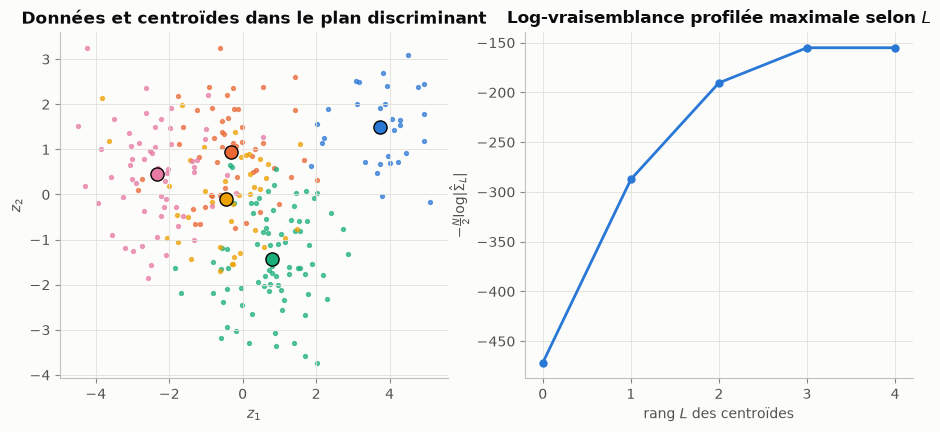

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
Z8 = (X8 - xbar) @ VL
cls5 = COLORS[:K8]
for k in range(K8):
    axes[0].scatter(*Z8[g8 == k].T, s=8, color=cls5[k], alpha=0.7)
    axes[0].scatter(*Zk[k], s=90, color=cls5[k], edgecolor="k", zorder=3)
axes[0].set_title("Données et centroïdes dans le plan discriminant")
axes[0].set_xlabel("$z_1$")
axes[0].set_ylabel("$z_2$")
lik = [-profil(xbar + (xbar_k - xbar) @ V8[:, :l] @ V8[:, :l].T @ W8) if l > 0 else -profil(np.tile(xbar, (K8, 1)))
       for l in range(p8 + 1)]
axes[1].plot(range(p8 + 1), N8 / 2 * np.array(lik), "o-", color=BLUE)
axes[1].set_title("Log-vraisemblance profilée maximale selon $L$")
axes[1].set_xlabel("rang $L$ des centroïdes")
axes[1].set_ylabel(r"$-\frac{N}{2}\log|\hat\Sigma_L|$")
axes[1].set_xticks(range(p8 + 1))
plt.show()

À droite : la vraisemblance maximale croît avec $L$ (modèles emboîtés) ; chaque dimension
ajoutée apporte $\frac N2\log(1+\lambda_L)$, d'autant moins que $\lambda_L$ est petit. Cela
fournit un critère (test du rapport de vraisemblance, ou AIC/BIC, chapitre 7) pour choisir $L$.

> **À retenir.** Le maximum de vraisemblance du modèle gaussien à covariance commune et
> centroïdes de rang $L$ projette les centroïdes sur les $L$ premières **variables
> canoniques** et reporte la dispersion des autres directions dans $\hat\Sigma$. Sa règle
> de Bayes est la classification au centroïde le plus proche dans le sous-espace
> discriminant de dimension $L$ : la LDA de rang réduit est un vrai modèle statistique.

## Exercice 4.9 : Programmer la QDA

**Énoncé.** Écrire un programme réalisant une analyse discriminante quadratique en
ajustant un modèle gaussien distinct par classe. L'essayer sur les données de voyelles et
calculer l'erreur de classification sur l'échantillon de test.

### Rappels

Chaque classe $k$ suit $\mathcal{N}(\mu_k,\Sigma_k)$ ; on estime
$\hat\pi_k = N_k/N$, $\hat\mu_k = \bar x_k$ et
$\hat\Sigma_k = \frac{1}{N_k-1}\sum_{g_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^T$. On classe vers
le plus grand discriminant quadratique (éq. (4.12))
$$\delta_k(x) = -\tfrac12\log|\hat\Sigma_k| - \tfrac12(x-\hat\mu_k)^T\hat\Sigma_k^{-1}(x-\hat\mu_k) + \log\hat\pi_k.$$

**Calcul stable.** Avec la factorisation de Cholesky $\hat\Sigma_k = \mathbf{L}_k\mathbf{L}_k^T$ :
$\log|\hat\Sigma_k| = 2\sum_j\log(\mathbf{L}_k)_{jj}$ et
$(x-\hat\mu_k)^T\hat\Sigma_k^{-1}(x-\hat\mu_k) = \|\mathbf{L}_k^{-1}(x-\hat\mu_k)\|^2$, où
$\mathbf{L}_k^{-1}(x-\hat\mu_k)$ s'obtient par résolution d'un système triangulaire (on
n'inverse jamais de matrice).

### Le programme

Voici une version autonome (la fonction `qda_fit` / `qda_predict` du module suit la même
logique, avec en plus l'option de régularisation de la RDA).

In [ ]:
def qda_entrainer(X, y):
    """Ajuste une gaussienne par classe ; renvoie (classes, log pi, moyennes, facteurs de Cholesky)."""
    classes = np.unique(y)
    logpi, moy, chol = [], [], []
    for k in classes:
        Xk = X[y == k]
        mk = Xk.mean(axis=0)
        Sk = (Xk - mk).T @ (Xk - mk) / (len(Xk) - 1)
        logpi.append(np.log(len(Xk) / len(y)))
        moy.append(mk)
        chol.append(np.linalg.cholesky(Sk))
    return classes, np.array(logpi), np.array(moy), chol

def qda_predire(modele, X):
    """Classe de plus grand discriminant quadratique delta_k(x)."""
    classes, logpi, moy, chol = modele
    delta = np.empty((len(X), len(classes)))
    for k, Lk in enumerate(chol):
        Zk = linalg.solve_triangular(Lk, (X - moy[k]).T, lower=True)   # L_k^{-1}(x - mu_k)
        delta[:, k] = -np.sum(np.log(np.diag(Lk))) - 0.5 * np.sum(Zk ** 2, axis=0) + logpi[k]
    return classes[np.argmax(delta, axis=1)]